# 05 — O incidente da semana de 20/11/2023 (enunciado §4.2)

**A pergunta da gerente:** o retorno em 7 dias de quem chegou na semana de 20/11/2023 caiu de 31% para 18% no
dashboard. O relatório do time de dados, que conta por `hashed_ip`, mostra 30% estável. O que aconteceu?

**O que este notebook faz** (a resposta escrita está em [docs/INCIDENTE.md](../docs/INCIDENTE.md)):
1. Confere se os números do enunciado existem na base pública.
2. Roda o código de referência do enunciado (carga + endpoint) sobre a nossa base e mede o efeito da chave
   IP + user-agent.
3. Testa 2 mecanismos que mudam o user-agent e vê qual reproduz a **assinatura** do incidente.
4. Mede os 4 defeitos secundários, um de cada vez.

O código de referência e a correção estão em [etl/incidente.py](../etl/incidente.py), o mesmo código que o
teste de regressão ([tests/test_incidente.py](../tests/test_incidente.py)) usa.

**A assinatura do incidente:** os novos quase dobram (1.172 → 2.034, +862) e os retornos ficam parados
(352 → 366). Logo, entraram cerca de 860 "novos" que **não voltam**. Uma hipótese só explica o incidente se
reproduzir as duas metades: denominador para cima, numerador parado.

In [2]:
from estilo import AZUL, BRUTA, LARANJA, RAIZ, TINTA_MUDA, aplicar, nota  # põe etl/ no path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
from incidente import CHAVE_CORRIGIDA, CHAVE_REFERENCIA, TABELA, carregar, confirmar, coortes, criar_tabela

aplicar()
pd.set_option("display.width", 180)
WORK = RAIZ / "data" / "work" / "incidente"
WORK.mkdir(parents=True, exist_ok=True)
SEMANAS = ("2023-11-06", "2023-11-27")  # as 3 semanas do enunciado (fim exclusivo, como no endpoint)
FONTE = "Fonte: WildChat-1M, Brasil · etl/incidente.py"


def conexao() -> duckdb.DuckDBPyConnection:
    con = duckdb.connect()
    con.execute("SET TimeZone = 'UTC'; SET memory_limit = '2GB'; SET enable_progress_bar = false")
    return con


def endpoint(bruta: str, corrigida: bool, chave: str | None = None, inicio: str = SEMANAS[0],
             fim: str = SEMANAS[1]) -> pd.DataFrame:
    con = conexao()
    criar_tabela(con, corrigida)
    carregar(con, bruta, corrigida, chave)
    return coortes(con, inicio, fim, corrigida)

## 1. Os números do enunciado não estão na base pública

O endpoint de referência, rodado sobre o recorte Brasil, devolve dezenas de novatos por semana, não milhares.
Os números do enunciado são ilustrativos. Por isso, a investigação demonstra o **mecanismo** com dados reais,
e não tenta reproduzir 2.034.

In [3]:
ref = endpoint(BRUTA, corrigida=False)
rel = endpoint(BRUTA, corrigida=False, chave="sha256(hashed_ip)")  # o "relatório": mesma lógica, chave por IP
comparacao = ref.merge(rel, on="semana", suffixes=("_dashboard", "_relatorio"))
display(comparacao.round(3))
# 1. Na nossa base, a semana de 20/11 tem 76 novatos pelo dashboard de referência e 68 pelo relatório (por IP),
#    não 2.034 e 1.172.
# 2. Por coincidência, o dashboard de referência também cai na nossa base (31,1% → 21,1%), e o relatório cai menos
#    (24,0% → 19,1%). Com ~70 pessoas por semana, o IC é de ±15 p.p.: é variação de amostra, não o incidente.

/var/folders/_9/zswmxgyd4_177wfx8vbhcr6r0000gn/T/ipykernel_48922/3122918355.py:4: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(comparacao.round(3))


,semana,novos_dashboard,voltaram_7d_dashboard,taxa_dashboard,novos_relatorio,voltaram_7d_relatorio,taxa_relatorio
0,2023-11-06,57,20,0.351,43,12,0.279
1,2023-11-13,61,19,0.311,50,12,0.240
2,2023-11-20,76,16,0.211,68,13,0.191


## 2. A chave IP + user-agent infla o denominador o tempo todo

A consulta de confirmação ([etl/incidente.py](../etl/incidente.py), `SQL_CONFIRMACAO`) roda na base bruta, que tem
`hashed_ip` e user-agent. Para cada semana, conta os novos pelas duas chaves e quantas chaves "novas" pertencem a
um IP que já existia antes.

período todo: 2895 chaves IP+UA × 2385 IPs (razão 1.21); 17.6% das chaves 'novas' são de um IP que já existia


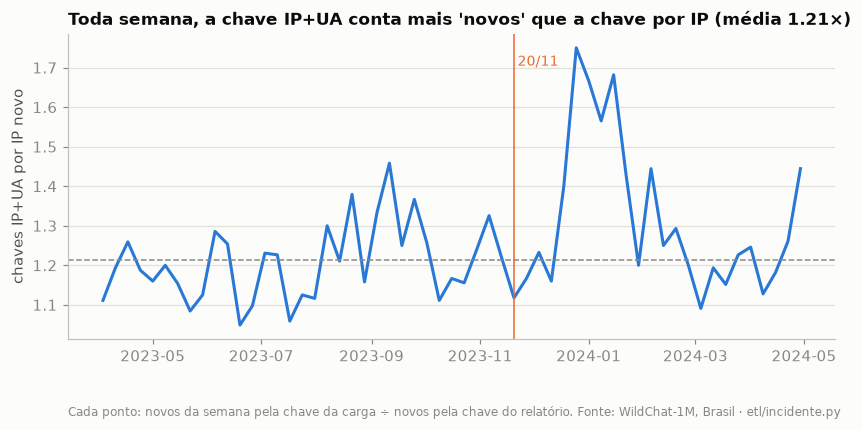

In [3]:
conf = confirmar(conexao(), BRUTA)
razao = conf.novos_ip_ua.sum() / conf.novos_ip.sum()
antigos = conf.ip_ja_existia.sum() / conf.novos_ip_ua.sum()
print(f"período todo: {conf.novos_ip_ua.sum()} chaves IP+UA × {conf.novos_ip.sum()} IPs (razão {razao:.2f}); "
      f"{antigos:.1%} das chaves 'novas' são de um IP que já existia")

fig, ax = plt.subplots()
ax.plot(pd.to_datetime(conf.semana), conf.razao_chaves_por_ip, color=AZUL, lw=2)
ax.axhline(razao, color=TINTA_MUDA, ls="--", lw=1)
ax.axvline(pd.Timestamp("2023-11-20"), color=LARANJA, lw=1)
ax.text(pd.Timestamp("2023-11-22"), ax.get_ylim()[1] * 0.97, "20/11", color=LARANJA, va="top", fontsize=9)
ax.set_ylabel("chaves IP+UA por IP novo")
ax.set_title(f"Toda semana, a chave IP+UA conta mais 'novos' que a chave por IP (média {razao:.2f}×)")
nota(ax, f"Cada ponto: novos da semana pela chave da carga ÷ novos pela chave do relatório. {FONTE}")
plt.show()
# 1. A chave IP+UA conta 21% mais "novos" que a chave por IP (2.895 × 2.385), em toda a base: é o "dashboard ~5%
#    acima" das semanas anteriores do enunciado, o mesmo defeito em escala menor.
# 2. 17,6% das chaves "novas" são de pessoas antigas que trocaram de user-agent (atualização de navegador, outro
#    aparelho na mesma rede). Elas entram no denominador como novatos.
# 3. A razão salta para 1,4–1,75 do fim de dezembro a janeiro: são as férias, com poucos novatos por semana, e a
#    razão fica instável. A semana de 20/11 está na média: na base pública, nada mudou no user-agent nessa data.

## 3. Qual mecanismo produz a assinatura do incidente?

Simulação controlada sobre os dados reais: a partir de 20/11/2023, o user-agent muda de 2 formas. O resto da
base fica igual. Cada versão passa pelo código de referência (dashboard) e pela chave por IP (relatório).

| Mecanismo | O que muda a partir de 20/11 |
|---|---|
| M1 — atualização de navegador | o user-agent de **todo mundo** muda uma vez (versão nova) |
| M2 — user-agent por conversa | em **metade das conversas**, o user-agent passa a ter um código único (ex.: uma versão do app que manda um identificador de sessão no cabeçalho) |

In [4]:
def simular(nome: str, novo_ua: str) -> str:
    """Grava uma cópia da base bruta com o user-agent alterado a partir de 20/11/2023."""
    destino = WORK / f"bruta_{nome}.parquet"
    conexao().execute(f"""
        COPY (
            SELECT * REPLACE (struct_pack("accept-language" := header."accept-language",
                                          "user-agent" := CASE WHEN timestamp >= TIMESTAMPTZ '2023-11-20'
                                                               THEN {novo_ua} ELSE header."user-agent" END) AS header)
            FROM read_parquet('{BRUTA}')
        ) TO '{destino}' (FORMAT parquet)
    """)
    return str(destino)


m1 = simular("m1_atualizacao", "header.\"user-agent\" || ' Versao/2'")
m2 = simular("m2_por_conversa", "CASE WHEN hash(conversation[1].turn_identifier) % 2 = 0 "
                                "THEN header.\"user-agent\" || ' sessao/' || conversation[1].turn_identifier "
                                "ELSE header.\"user-agent\" END")

linhas = []
for cenario, arq in (("real", BRUTA), ("M1 atualização", m1), ("M2 por conversa", m2)):
    for conta, chave in (("dashboard (IP+UA)", CHAVE_REFERENCIA), ("relatório (IP)", "sha256(hashed_ip)")):
        r = endpoint(arq, corrigida=False, chave=chave)
        s = r[r.semana == pd.Timestamp("2023-11-20")].iloc[0]
        linhas.append({"cenário": cenario, "conta": conta, "novos": int(s.novos), "voltaram": int(s.voltaram_7d),
                       "taxa": s.taxa})
sim = pd.DataFrame(linhas)
display(sim.pivot(index="cenário", columns="conta", values=["novos", "voltaram", "taxa"]).round(3))

novos                         voltaram                             taxa               
conta           dashboard (IP+UA) relatório (IP) dashboard (IP+UA) relatório (IP) dashboard (IP+UA) relatório (IP)
cenário                                                                                                           
M1 atualização               90.0           68.0              26.0           13.0             0.289          0.191
M2 por conversa             147.0           68.0              11.0           13.0             0.075          0.191
real                         76.0           68.0              16.0           13.0             0.211          0.191

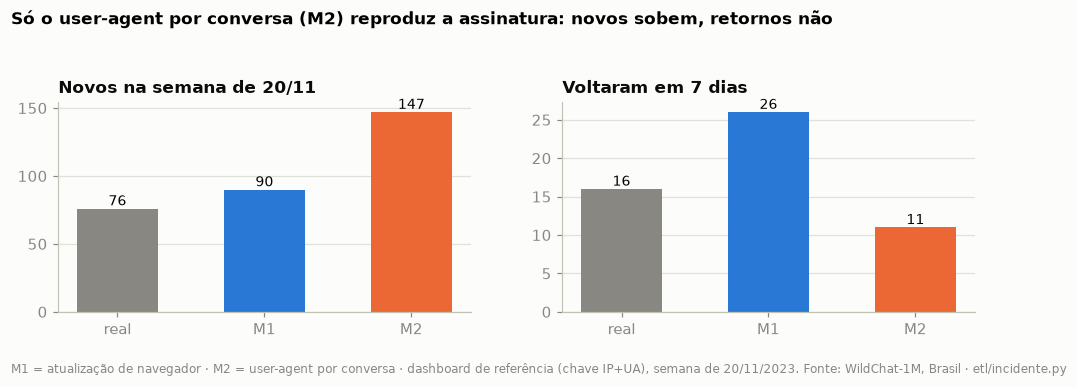

In [5]:
d = sim[sim.conta == "dashboard (IP+UA)"].set_index("cenário")
d.index = ["real", "M1", "M2"]
fig, axs = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, col, titulo in ((axs[0], "novos", "Novos na semana de 20/11"), (axs[1], "voltaram", "Voltaram em 7 dias")):
    ax.bar(d.index, d[col], color=[TINTA_MUDA, AZUL, LARANJA], width=0.55)
    for i, v in enumerate(d[col]):
        ax.text(i, v, f"{v}", ha="center", va="bottom", fontsize=9)
    ax.set_title(titulo)
fig.suptitle("Só o user-agent por conversa (M2) reproduz a assinatura: novos sobem, retornos não", x=0.01,
             ha="left", fontsize=11, fontweight="bold")
fig.text(0.01, 0.01, "M1 = atualização de navegador · M2 = user-agent por conversa · dashboard de referência "
         f"(chave IP+UA), semana de 20/11/2023. {FONTE}", fontsize=8, color=TINTA_MUDA)
plt.tight_layout(rect=(0, 0.06, 1, 0.93), w_pad=4)
plt.show()
# 1. M1 (atualização de navegador): as pessoas antigas viram chaves novas, mas continuam ativas e voltam. Os novos
#    sobem (76 → 90) e os retornos sobem junto (16 → 26): NÃO é a assinatura do enunciado.
# 2. M2 (user-agent por conversa): cada conversa marcada vira uma chave que aparece uma vez e nunca volta. Os
#    novos quase dobram (76 → 147) e os retornos não sobem (16 → 11): É a assinatura (no enunciado: +862 novos,
#    retornos 352 → 366).
# 3. O relatório (chave por IP) fica igual nos 3 cenários (68 novos, 13 voltaram): o defeito está na chave da
#    carga, não no comportamento das pessoas.

## 4. Os 4 defeitos secundários, um de cada vez

Ponto de partida: o código de referência inteiro. Cada linha corrige **um** defeito e mantém os outros. A última
linha é a versão corrigida inteira ([etl/incidente.py](../etl/incidente.py)). Período: a base inteira.

O defeito do `EXISTS` sem país só aparece com as conversas que os mesmos IPs tiveram fora do Brasil. Por isso,
esta seção usa as conversas dos IPs brasileiros em qualquer país (a população continua sendo a do Brasil).

In [6]:
ips_mundo = WORK / "ips_br_no_mundo.parquet"
conexao().execute(f"""
    COPY (SELECT * FROM read_parquet('{RAIZ}/data/raw/wildchat-1m/*.parquet')
          WHERE hashed_ip IN (SELECT DISTINCT hashed_ip FROM read_parquet('{BRUTA}')))
    TO '{ips_mundo}' (FORMAT parquet)
""")
fora = conexao().execute(f"SELECT count(*) FILTER (WHERE country <> 'Brazil'), count(*) FROM '{ips_mundo}'").fetchone()
print(f"conversas dos IPs brasileiros: {fora[1]}; fora do Brasil: {fora[0]} ({fora[0] / fora[1]:.1%})")


def variante(chave: str, primeiro_turno: bool, fuso: bool, pais_no_exists: bool) -> tuple[int, int]:
    con = conexao()
    criar_tabela(con, corrigida=True)
    carregar(con, str(ips_mundo), corrigida=True, chave=chave)
    t = "primeiro_turno" if primeiro_turno else "ultimo_turno"
    semana = "timezone('America/Sao_Paulo', p.primeira_vez)" if fuso else "p.primeira_vez"
    filtro = "AND c.pais = 'Brazil'" if pais_no_exists else ""
    return con.execute(f"""
        WITH primeira AS (SELECT usuario_id, min({t}) AS primeira_vez FROM {TABELA}
                          WHERE pais = 'Brazil' GROUP BY 1)
        SELECT count(*), count(*) FILTER (WHERE EXISTS (
                   SELECT 1 FROM {TABELA} c WHERE c.usuario_id = p.usuario_id {filtro}
                     AND c.{t} > p.primeira_vez + INTERVAL 1 HOUR AND c.{t} <= p.primeira_vez + INTERVAL 7 DAY))
        FROM primeira p WHERE date_trunc('week', {semana}) IS NOT NULL
    """).fetchone()


casos = {
    "referência (todos os defeitos)": (CHAVE_REFERENCIA, False, False, False),
    "1. chave = IP (BDR-001)": (CHAVE_CORRIGIDA, False, False, False),
    "2. 1ª vez pelo 1º turno": (CHAVE_REFERENCIA, True, False, False),
    "3. semana no fuso de São Paulo": (CHAVE_REFERENCIA, False, True, False),
    "4. EXISTS filtra o país": (CHAVE_REFERENCIA, False, False, True),
    "corrigida (as 4 correções)": (CHAVE_CORRIGIDA, True, True, True),
}
tab = pd.DataFrame([(nome, *variante(*args)) for nome, args in casos.items()], columns=["caso", "novos", "voltaram"])
tab["taxa"] = tab.voltaram / tab.novos
base = tab.iloc[0]
tab["Δ novos"] = tab.novos - base.novos
tab["Δ taxa (p.p.)"] = 100 * (tab.taxa - base.taxa)
display(tab.round(3))
# 1. A chave é o defeito que pesa: só ela muda o denominador (510 "novos" falsos na base inteira, 2.895 → 2.385) e
#    a taxa (−2,0 p.p.).
# 2. O último turno no lugar do 1º muda pouco (−0,1 p.p.). O fuso não muda o total, só a semana em que a pessoa
#    cai (medido abaixo).
# 3. O EXISTS sem país não tem efeito aqui: os IPs brasileiros não têm nenhuma conversa fora do Brasil na base
#    pública. É um defeito latente (VPN, roaming), que o teste de regressão cobre.
# 4. O 5º defeito (ON CONFLICT DO NOTHING) só aparece com cargas diárias de uma conversa que continua no dia
#    seguinte. Não dá para medir na base pública (cada conversa vem uma vez); o teste de regressão cobre o caso.

conversas dos IPs brasileiros: 11621; fora do Brasil: 0 (0.0%)


,caso,novos,voltaram,taxa,Δ novos,Δ taxa (p.p.)
0,referência (todos os defeitos),2895,745,0.257,0,0.000
1,1. chave = IP (BDR-001),2385,566,0.237,-510,-2.002
2,2. 1ª vez pelo 1º turno,2895,742,0.256,0,-0.104
3,3. semana no fuso de São Paulo,2895,745,0.257,0,0.000
4,4. EXISTS filtra o país,2895,745,0.257,0,0.000
5,corrigida (as 4 correções),2385,564,0.236,-510,-2.086


In [7]:
muda = conexao().execute(f"""
    WITH p AS (SELECT hashed_ip, min(list_min(list_transform(conversation, lambda t: t.timestamp))) AS t0
               FROM read_parquet('{BRUTA}') GROUP BY 1)
    SELECT count(*) FILTER (WHERE date_trunc('week', t0) <> date_trunc('week', timezone('America/Sao_Paulo', t0))),
           count(*)
    FROM p
""").fetchone()
print(f"novatos que mudam de semana entre UTC e São Paulo: {muda[0]} de {muda[1]} ({muda[0] / muda[1]:.1%})")
# Domingo entre 21h e 23h59 em São Paulo já é segunda em UTC: essas pessoas caem na semana seguinte no endpoint
# de referência.

novatos que mudam de semana entre UTC e São Paulo: 46 de 2385 (1.9%)


## 5. Conclusão

1. **Camada da falha: a carga.** A chave `sha256(hashed_ip|user-agent)` transforma qualquer variação do
   user-agent em "usuário novo". O endpoint e a tela só repetem o que a base analítica tem.
2. **O mecanismo que reproduz a assinatura** (novos sobem, retornos não): o user-agent passa a variar por conversa
   numa parte do tráfego a partir de 20/11. Uma atualização de navegador comum não basta: ela faria os retornos
   subirem junto.
3. **A consulta de confirmação** roda na base bruta: nas semanas antes e depois de 20/11, a razão "chaves por IP"
   e a % de chaves "novas" de IPs que já existiam. Se a razão salta na semana de 20/11, a hipótese se confirma.
4. **A correção** está em [etl/incidente.py](../etl/incidente.py) (`corrigida=True`) e é protegida por
   [tests/test_incidente.py](../tests/test_incidente.py). A nossa carga já usa a chave por IP (BDR-001).